In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
final_df = pd.read_csv("../data/processed/ml_dataset.csv")

In [4]:
final_df.shape

(109200, 54)

In [5]:
final_df.isnull().sum()

product_id                             0
product_name                           0
year                                   0
month                                  0
month_number                           0
monthly_revenue                        0
unique_customers                     191
units_per_customer                   191
revenue_per_customer                 191
next_monthly_revenue                1820
is_quarter_end                         0
is_year_end                            0
trend_year                             0
sin_month                              0
cos_month                              0
monthly_quantity                       0
monthly_transactions                   0
lag_1_revenue                       1820
lag_2_revenue                       3640
lag_3_revenue                       5460
lag_12_revenue                     21840
lag_1_quantity                      1820
lag_2_quantity                      3640
lag_3_quantity                      5460
lag_12_quantity 

##### Handling Null Values

In [6]:
int(final_df['year'].isna().sum())

0

In [7]:
final_df['lag_1_revenue'].count()

np.int64(107380)

In [8]:
import calendar

# Maps numbers (1-12) to full month names
final_df['month_name'] = final_df['month_number'].map(lambda x: calendar.month_name[int(x)] if pd.notna(x) else x)

In [9]:
import calendar
import pandas as pd

# 1. Filter and get unique combinations
df_unique = final_df[final_df['lag_12_revenue'].isna()][['year', 'month_number']].drop_duplicates()

# Ensure month_number is an integer to sort properly
df_unique['month_number'] = df_unique['month_number'].astype(int)

# 2. Group by 'year' and find the min/max months
summary = df_unique.groupby('year')['month_number'].agg(['min', 'max']).reset_index()


# 3. Create a helper function to format the string
def format_range(row):
    year = int(row['year'])
    min_month = calendar.month_abbr[row['min']]
    max_month = calendar.month_abbr[row['max']]

    # If it's a single month, don't show a range (e.g., "Jan 2021")
    if min_month == max_month:
        return f"{min_month} {year}"
    # Otherwise, return the range (e.g., "Jan-Mar 2021")
    return f"{min_month}-{max_month} {year}"


# 4. Apply the function to get your final value(s)
summary['formatted_range'] = summary.apply(format_range, axis=1)

# Display the results
print(summary['formatted_range'].tolist())

print(summary)

['Jan-Dec 2021']
   year  min  max formatted_range
0  2021    1   12    Jan-Dec 2021


In [10]:
def null_value_summary(df):
    null_feature_set = []
    for col in df.columns:
        feature = col
        null_count = int(df[col].isna().sum())
        null_percent = (null_count / len(df[col]))*100
        df_unique = (df[df[col].isna()][['year', 'month_number']].drop_duplicates())

        affected_periods = []

        if not df_unique.empty:
            df_unique['month_number'] = df_unique['month_number'].astype(int)

            for year, group in df_unique.groupby('year'):
                months = sorted(group['month_number'].unique())

                # Split months into consecutive ranges
                ranges = []
                start = prev = months[0]

                for month in months[1:]:
                    if month == prev + 1:
                        prev = month
                    else:
                        ranges.append((start, prev))
                        start = prev = month

                ranges.append((start, prev))

                # Format each range
                for min_month, max_month in ranges:
                    year = int(year)
                    min_month_name = calendar.month_abbr[min_month]
                    max_month_name = calendar.month_abbr[max_month]

                    if min_month == max_month:
                        period = f"{min_month_name} {year}"
                    else:
                        period = f"{min_month_name}-{max_month_name} {year}"

                    affected_periods.append(period)
        null_feature_set.append({'Feature': feature, 'Null Count': null_count, 'Null Percent': null_percent, 'Affected Period': affected_periods})
    null_feature_set = pd.DataFrame(null_feature_set)
    return null_feature_set

In [11]:
null_value_summary(final_df)

,Feature,Null Count,Null Percent,Affected Period
0,product_id,0,0.000000,[]
1,product_name,0,0.000000,[]
2,year,0,0.000000,[]
3,month,0,0.000000,[]
4,month_number,0,0.000000,[]
5,monthly_revenue,0,0.000000,[]
6,unique_customers,191,0.174908,"[Jan-Dec 2021, Jan-Dec 2022, Jan-Dec 2023, Jan..."
7,units_per_customer,191,0.174908,"[Jan-Dec 2021, Jan-Dec 2022, Jan-Dec 2023, Jan..."
8,revenue_per_customer,191,0.174908,"[Jan-Dec 2021, Jan-Dec 2022, Jan-Dec 2023, Jan..."
9,next_monthly_revenue,1820,1.666667,[Dec 2025]


In [12]:
final_df.columns

Index(['product_id', 'product_name', 'year', 'month', 'month_number',
       'monthly_revenue', 'unique_customers', 'units_per_customer',
       'revenue_per_customer', 'next_monthly_revenue', 'is_quarter_end',
       'is_year_end', 'trend_year', 'sin_month', 'cos_month',
       'monthly_quantity', 'monthly_transactions', 'lag_1_revenue',
       'lag_2_revenue', 'lag_3_revenue', 'lag_12_revenue', 'lag_1_quantity',
       'lag_2_quantity', 'lag_3_quantity', 'lag_12_quantity',
       'lag_1_transactions', 'lag_2_transactions', 'lag_3_transactions',
       'lag_12_transactions', 'moving_avg_3_month', 'moving_avg_6_month',
       'moving_avg_12_month', 'month_over_month', 'year_on_year',
       'moving_stdev_3_month', 'moving_stdev_6_month', 'momentum',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'average_discount_pct', 'maximum_discount',
       'total_discount_amount', 'pct_transactions_discount_gt_10',
       'pct_transactions_discoun

In [13]:
final_df.shape

(109200, 55)

In [14]:
final_df['next_monthly_revenue'].isna().sum()

np.int64(1820)

In [15]:
print("Mean:", final_df['next_monthly_revenue'].mean())
print("Minimum:", final_df['next_monthly_revenue'].min())
print("Maximum:", final_df['next_monthly_revenue'].max())
print("Median:", final_df['next_monthly_revenue'].median())

Mean: 52436.23715561558
Minimum: 0.0
Maximum: 2968515.0
Median: 17356.59


##### Distribution of Target Variable

(array([1.03331e+05, 2.61500e+03, 9.23000e+02, 3.15000e+02, 1.27000e+02,
        4.20000e+01, 1.90000e+01, 5.00000e+00, 2.00000e+00, 1.00000e+00]),
 array([      0. ,  296851.5,  593703. ,  890554.5, 1187406. , 1484257.5,
        1781109. , 2077960.5, 2374812. , 2671663.5, 2968515. ]),
 <BarContainer object of 10 artists>)

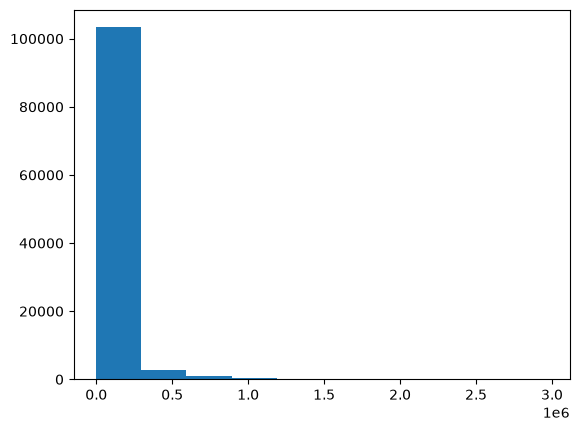

In [16]:
plt.hist(final_df['next_monthly_revenue'])

##### Missing values for Predictors

In [17]:
null_counts = final_df.isna().sum()

In [18]:
null_counts[null_counts > 0]

unique_customers            191
units_per_customer          191
revenue_per_customer        191
next_monthly_revenue       1820
lag_1_revenue              1820
lag_2_revenue              3640
lag_3_revenue              5460
lag_12_revenue            21840
lag_1_quantity             1820
lag_2_quantity             3640
lag_3_quantity             5460
lag_12_quantity           21840
lag_1_transactions         1820
lag_2_transactions         3640
lag_3_transactions         5460
lag_12_transactions       21840
moving_avg_3_month         3640
moving_avg_6_month         9100
moving_avg_12_month       20020
month_over_month           2010
year_on_year              21994
moving_stdev_3_month       3640
moving_stdev_6_month       9100
momentum                   5462
category_revenue_share      191
category_unit_share         191
total_profit                191
average_profit              191
dtype: int64

In [19]:
final_df.duplicated().sum()

np.int64(0)

In [20]:
final_df.dtypes

product_id                             str
product_name                           str
year                                 int64
month                                  str
month_number                         int64
monthly_revenue                    float64
unique_customers                   float64
units_per_customer                 float64
revenue_per_customer               float64
next_monthly_revenue               float64
is_quarter_end                       int64
is_year_end                          int64
trend_year                           int64
sin_month                          float64
cos_month                          float64
monthly_quantity                     int64
monthly_transactions                 int64
lag_1_revenue                      float64
lag_2_revenue                      float64
lag_3_revenue                      float64
lag_12_revenue                     float64
lag_1_quantity                     float64
lag_2_quantity                     float64
lag_3_quant

In [21]:
print(final_df.isin([float('inf'), float('-inf')]).sum())

product_id                         0
product_name                       0
year                               0
month                              0
month_number                       0
monthly_revenue                    0
unique_customers                   0
units_per_customer                 0
revenue_per_customer               0
next_monthly_revenue               0
is_quarter_end                     0
is_year_end                        0
trend_year                         0
sin_month                          0
cos_month                          0
monthly_quantity                   0
monthly_transactions               0
lag_1_revenue                      0
lag_2_revenue                      0
lag_3_revenue                      0
lag_12_revenue                     0
lag_1_quantity                     0
lag_2_quantity                     0
lag_3_quantity                     0
lag_12_quantity                    0
lag_1_transactions                 0
lag_2_transactions                 0
l

In [22]:
final_df.describe()

,year,month_number,monthly_revenue,unique_customers,units_per_customer,revenue_per_customer,next_monthly_revenue,is_quarter_end,is_year_end,trend_year,...,pct_transactions_discount_gt_10,pct_transactions_discount_gt_15,average_selling_price,minimum_selling_price,maximum_selling_price,price_range,non_discounted_revenue,discounted_revenue,discounted_quantity_sold,discounted_orders
count,109200.00000,109200.000000,1.092000e+05,109009.000000,109009.000000,109009.000000,1.073800e+05,109200.000000,109200.000000,109200.00000,...,109200.000000,109200.000000,109200.000000,109200.000000,109200.000000,109200.000000,109200.000000,1.092000e+05,109200.000000,109200.000000
mean,2023.00000,6.500000,5.251445e+04,6.417388,2.982607,8225.723337,5.243624e+04,0.333333,0.083333,2.00000,...,43.840015,22.676852,8206.159316,4668.886716,11931.145671,7262.258955,3095.958700,4.941849e+04,20.614908,6.159707
std,1.41422,3.452068,1.272902e+05,2.526660,1.773634,18437.190661,1.269906e+05,0.471407,0.276387,1.41422,...,40.205789,33.600955,18411.981446,12482.533946,24992.211811,13662.257048,16895.892734,1.189019e+05,13.361469,2.500617
min,2021.00000,1.000000,0.000000e+00,1.000000,1.000000,13.960000,0.000000e+00,0.000000,0.000000,0.00000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2022.00000,3.750000,7.562122e+03,5.000000,2.000000,1372.910000,7.561250e+03,0.000000,0.000000,1.00000,...,0.000000,0.000000,1366.730000,540.000000,2153.210000,1362.750000,0.000000,7.243100e+03,11.000000,4.000000
50%,2023.00000,6.500000,1.736232e+04,6.000000,2.000000,2937.000000,1.735659e+04,0.000000,0.000000,2.00000,...,40.000000,0.000000,2928.595000,1278.000000,4554.000000,3018.885000,0.000000,1.679322e+04,17.000000,6.000000
75%,2024.00000,9.250000,3.944257e+04,8.000000,4.000000,6136.260000,3.938295e+04,1.000000,0.000000,3.00000,...,85.710000,50.000000,6122.782500,2779.930000,9541.800000,6543.420000,0.000000,3.807527e+04,27.000000,8.000000
max,2025.00000,12.000000,2.968515e+06,20.000000,11.000000,286605.000000,2.968515e+06,1.000000,1.000000,4.00000,...,100.000000,100.000000,286605.000000,282150.000000,297000.000000,170775.000000,742500.000000,2.472525e+06,114.000000,20.000000


<Axes: >

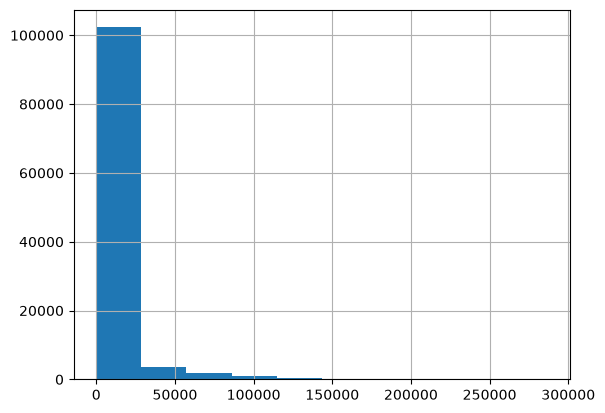

In [23]:
final_df['average_selling_price'].hist()

In [24]:
final_df.groupby('product_id').apply(lambda x: x.nlargest(10, 'average_selling_price')).reset_index(drop=True)

,product_name,year,month,month_number,monthly_revenue,unique_customers,units_per_customer,revenue_per_customer,next_monthly_revenue,is_quarter_end,...,pct_transactions_discount_gt_15,average_selling_price,minimum_selling_price,maximum_selling_price,price_range,non_discounted_revenue,discounted_revenue,discounted_quantity_sold,discounted_orders,month_name
0,Premium Rice 500g,2022,March,3,1293.07,3.0,8.0,431.02,1601.95,1,...,0.0,431.02,347.42,475.20,127.78,0.0,1293.07,26,3,March
1,Premium Rice 500g,2022,April,4,1601.95,4.0,7.0,400.49,3174.87,0,...,0.0,400.49,362.21,451.44,89.23,422.4,1179.55,23,3,April
2,Premium Rice 500g,2023,January,1,1992.67,5.0,8.0,398.53,2167.97,0,...,0.0,398.53,240.24,485.76,245.52,0.0,1992.67,41,5,January
3,Premium Rice 500g,2022,June,6,2984.79,8.0,7.0,373.10,2133.64,1,...,0.0,373.10,194.30,465.70,271.40,0.0,2984.79,60,8,June
4,Premium Rice 500g,2025,January,1,2941.49,8.0,7.0,367.69,690.62,0,...,0.0,367.69,192.19,506.88,314.69,0.0,2941.49,58,8,January
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18195,Router Premium 512GB,2024,November,11,88155.00,8.0,1.0,11019.38,43200.00,0,...,0.0,11019.38,5737.50,13500.00,7762.50,13500.0,74655.00,12,7,November
18196,Router Premium 512GB,2022,May,5,43807.50,4.0,1.0,10951.88,24705.00,0,...,0.0,10951.88,6547.50,13230.00,6682.50,0.0,43807.50,7,4,May
18197,Router Premium 512GB,2022,October,10,43605.00,4.0,1.0,10901.25,90855.00,0,...,0.0,10901.25,5805.00,13500.00,7695.00,13500.0,30105.00,5,3,October
18198,Router Premium 512GB,2021,November,11,86467.50,8.0,1.0,10808.44,69592.50,0,...,0.0,10808.44,6210.00,13230.00,7020.00,0.0,86467.50,14,8,November


##### Feature Selection Methods

--- Wrapper Method

<Axes: ylabel='next_monthly_revenue'>

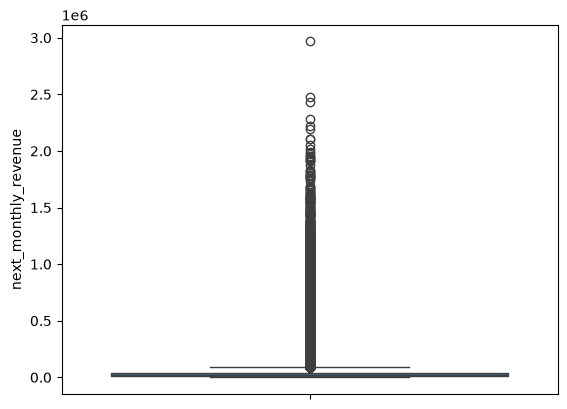

In [25]:
sns.boxplot(final_df['next_monthly_revenue'])

In [26]:
pd.set_option('display.float_format', lambda x: '%.0f' % x)

In [27]:
final_df['next_monthly_revenue'].describe()

count    107380
mean      52436
std      126991
min           0
25%        7561
50%       17357
75%       39383
max     2968515
Name: next_monthly_revenue, dtype: float64

In [28]:
final_df['next_monthly_revenue'].skew()

np.float64(6.204905104548526)

In [29]:
Q1 = final_df['next_monthly_revenue'].quantile(0.25)
Q3 = final_df['next_monthly_revenue'].quantile(0.75)

IQR = Q3 - Q1
IQR

np.float64(31821.699999999997)

In [30]:
final_df.select_dtypes(include=['object', 'category']).columns

C:\Users\rkalbag\AppData\Local\Temp\ipykernel_19108\3870068059.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  final_df.select_dtypes(include=['object', 'category']).columns


Index(['product_id', 'product_name', 'month', 'month_name'], dtype='str')

In [31]:
final_df.select_dtypes(include='number').columns

Index(['year', 'month_number', 'monthly_revenue', 'unique_customers',
       'units_per_customer', 'revenue_per_customer', 'next_monthly_revenue',
       'is_quarter_end', 'is_year_end', 'trend_year', 'sin_month', 'cos_month',
       'monthly_quantity', 'monthly_transactions', 'lag_1_revenue',
       'lag_2_revenue', 'lag_3_revenue', 'lag_12_revenue', 'lag_1_quantity',
       'lag_2_quantity', 'lag_3_quantity', 'lag_12_quantity',
       'lag_1_transactions', 'lag_2_transactions', 'lag_3_transactions',
       'lag_12_transactions', 'moving_avg_3_month', 'moving_avg_6_month',
       'moving_avg_12_month', 'month_over_month', 'year_on_year',
       'moving_stdev_3_month', 'moving_stdev_6_month', 'momentum',
       'category_revenue_share', 'category_unit_share', 'total_profit',
       'average_profit', 'average_discount_pct', 'maximum_discount',
       'total_discount_amount', 'pct_transactions_discount_gt_10',
       'pct_transactions_discount_gt_15', 'average_selling_price',
       'min

##### Train Test Split

In [32]:
X = final_df.drop('next_monthly_revenue', axis=1)
y = final_df['next_monthly_revenue']

In [33]:
## Training Dataset
X_train = X[X['year'].between(2021, 2023)]
y_train = final_df.loc[final_df['year'].between(2021, 2023), ['next_monthly_revenue']]


## Validation Dataset (RFE)
X_validation = X[X['year'] == (2024)]
y_validation = final_df.loc[final_df['year'] == 2024, ['next_monthly_revenue']]


## Test Dataset (To be used in final ML Modelling)
X_test = X[X['year'] == (2025)]
y_test = final_df.loc[final_df['year'] == 2025, ['next_monthly_revenue']]

<Axes: >

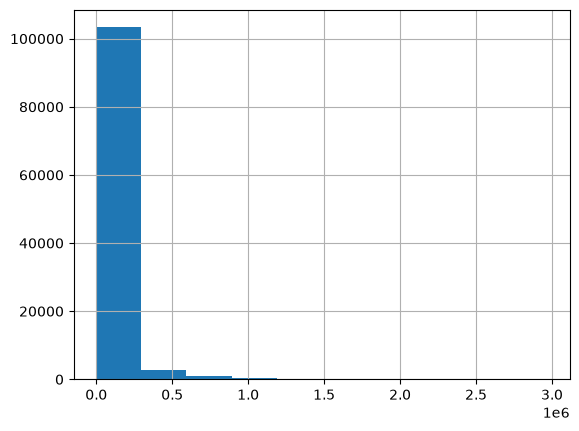

In [34]:
final_df['next_monthly_revenue'].hist()

In [35]:
print("X Train", X_train.shape)
print("X Test", X_test.shape)
print("X Validation", X_validation.shape)

print("y Train", y_train.shape)
print("y Test", y_test.shape)
print("y Validation", y_validation.shape)

X Train (65520, 54)
X Test (21840, 54)
X Validation (21840, 54)
y Train (65520, 1)
y Test (21840, 1)
y Validation (21840, 1)
